<a href="https://colab.research.google.com/github/PaoBatatus/projeto-queimadas/blob/main/notebooks/analise_queimadas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Queimadas

Análise exploratória de focos de queimadas e incêndios no Brasil usando dados do Programa Queimadas do INPE.

**Recorte inicial:** Brasil, 2012–2025, todos os satélites.  
**Status do recorte:** provisório; será confirmado após a contagem dos arquivos.

## Perguntas de pesquisa

1. Como o número de focos varia por mês e ano?
2. Quais UFs acumulam mais focos no período?
3. Em quais meses há mais focos?
4. Como varia a distribuição de focos entre satélites?
5. Quais UFs têm mais focos por 100 mil habitantes?

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJETO = Path("/content/drive/MyDrive/projeto-queimadas")
BRONZE = PROJETO / "data" / "bronze"
SILVER = PROJETO / "data" / "silver"
GOLD = PROJETO / "data" / "gold"

for pasta in [BRONZE, SILVER, GOLD]:
    pasta.mkdir(parents=True, exist_ok=True)

print("Pastas de trabalho prontas em:", PROJETO)

Mounted at /content/drive
Pastas de trabalho prontas em: /content/drive/MyDrive/projeto-queimadas


In [2]:
import requests

ano_teste = 2018
url_teste = (
    "https://dataserver-coids.inpe.br/queimadas/queimadas/"
    f"focos/csv/anual/Brasil_todos_sats/"
    f"focos_br_todos-sats_{ano_teste}.zip"
)

arquivo_teste = BRONZE / f"focos_{ano_teste}.zip"

resposta = requests.get(url_teste, stream=True, timeout=180)
resposta.raise_for_status()

with open(arquivo_teste, "wb") as destino:
    for bloco in resposta.iter_content(chunk_size=1024 * 1024):
        if bloco:
            destino.write(bloco)

print("Download concluído:", arquivo_teste.name)
print("Tamanho:", round(arquivo_teste.stat().st_size / 1024 / 1024, 2), "MB")

Download concluído: focos_2018.zip
Tamanho: 27.48 MB


In [3]:
import zipfile
import pandas as pd

with zipfile.ZipFile(arquivo_teste) as pacote:
    arquivos_csv = [
        nome for nome in pacote.namelist()
        if nome.lower().endswith(".csv")
    ]

    print("Arquivos CSV dentro do ZIP:")
    print(arquivos_csv)

    with pacote.open(arquivos_csv[0]) as arquivo:
        amostra = pd.read_csv(
            arquivo,
            sep=None,
            engine="python",
            nrows=5,
            encoding="utf-8-sig",
            encoding_errors="replace"
        )

print("\nColunas:")
print(amostra.columns.tolist())

print("\nTipos identificados:")
print(amostra.dtypes)

print("\nCinco linhas de exemplo:")
display(amostra)

Arquivos CSV dentro do ZIP:
['focos_br_todos-sats_2018.csv']

Colunas:
['latitude', 'longitude', 'data_pas', 'satelite', 'pais', 'estado', 'municipio', 'bioma', 'numero_dias_sem_chuva', 'precipitacao', 'risco_fogo', 'id_area_industrial', 'frp']

Tipos identificados:
latitude                 float64
longitude                float64
data_pas                  object
satelite                  object
pais                      object
estado                    object
municipio                 object
bioma                     object
numero_dias_sem_chuva      int64
precipitacao             float64
risco_fogo               float64
id_area_industrial         int64
frp                      float64
dtype: object

Cinco linhas de exemplo:


,latitude,longitude,data_pas,satelite,pais,estado,municipio,bioma,numero_dias_sem_chuva,precipitacao,risco_fogo,id_area_industrial,frp
0,2.46000,-61.19000,2018-03-01 23:05:45,GOES-16,Brasil,RORAIMA,MUCAJAÍ,Amazônia,0,0.7,0.9,0,NaN
1,-29.86929,-51.55051,2018-06-09 16:54:00,NPP-375,Brasil,RIO GRANDE DO SUL,TRIUNFO,Pampa,2,0.0,0.8,0,3.0
2,-13.16900,-59.93400,2018-06-09 14:20:00,TERRA_M-T,Brasil,MATO GROSSO,COMODORO,Amazônia,7,0.0,0.7,0,8.2
3,-13.17000,-59.92500,2018-06-09 14:20:00,TERRA_M-T,Brasil,MATO GROSSO,COMODORO,Amazônia,7,0.0,0.6,0,12.8
4,-13.57400,-56.87600,2018-06-09 14:20:00,TERRA_M-T,Brasil,MATO GROSSO,SÃO JOSÉ DO RIO CLARO,Cerrado,18,0.0,1.0,0,14.4


In [4]:
import zipfile
import pandas as pd

with zipfile.ZipFile(arquivo_teste) as pacote:
    csv_interno = next(
        nome for nome in pacote.namelist()
        if nome.lower().endswith(".csv")
    )

    total_linhas_2018 = 0

    with pacote.open(csv_interno) as arquivo:
        for lote in pd.read_csv(
            arquivo,
            sep=",",
            chunksize=250_000,
            low_memory=False
        ):
            total_linhas_2018 += len(lote)

print(f"Linhas no arquivo de 2018: {total_linhas_2018:,}")

Linhas no arquivo de 2018: 1,826,081


In [5]:
import time
import zipfile
import requests
import pandas as pd
from datetime import datetime
from pathlib import Path

anos_teste = [2018, 2019, 2020]
metadados = []

for ano in anos_teste:
    url = (
        "https://dataserver-coids.inpe.br/queimadas/queimadas/"
        f"focos/csv/anual/Brasil_todos_sats/"
        f"focos_br_todos-sats_{ano}.zip"
    )
    arquivo_zip = BRONZE / f"focos_{ano}.zip"

    if not arquivo_zip.exists():
        for tentativa in range(1, 4):
            try:
                resposta = requests.get(url, stream=True, timeout=180)
                resposta.raise_for_status()

                with open(arquivo_zip, "wb") as destino:
                    for bloco in resposta.iter_content(1024 * 1024):
                        if bloco:
                            destino.write(bloco)
                break
            except Exception:
                if tentativa == 3:
                    raise
                time.sleep(3)

    with zipfile.ZipFile(arquivo_zip) as pacote:
        csv_interno = next(
            nome for nome in pacote.namelist()
            if nome.lower().endswith(".csv")
        )

        linhas = 0
        colunas = None

        with pacote.open(csv_interno) as arquivo:
            for lote in pd.read_csv(
                arquivo,
                sep=",",
                chunksize=250_000,
                low_memory=False
            ):
                linhas += len(lote)
                if colunas is None:
                    colunas = len(lote.columns)

    metadados.append({
        "ano": ano,
        "url": url,
        "data_download": datetime.now().isoformat(timespec="seconds"),
        "arquivo": arquivo_zip.name,
        "linhas": linhas,
        "colunas": colunas,
        "tamanho_bytes": arquivo_zip.stat().st_size
    })

    print(f"{ano}: {linhas:,} linhas")

tabela_metadados = pd.DataFrame(metadados)
display(tabela_metadados)

total = tabela_metadados["linhas"].sum()
print(f"TOTAL 2018–2020: {total:,} linhas")
print("Atingiu 5 milhões?", total >= 5_000_000)

pasta_docs_drive = PROJETO / "docs"
pasta_docs_drive.mkdir(parents=True, exist_ok=True)
tabela_metadados.to_csv(
    pasta_docs_drive / "metadados_coleta.csv",
    index=False
)

2018: 1,826,081 linhas
2019: 4,070,300 linhas
2020: 5,212,990 linhas


,ano,url,data_download,arquivo,linhas,colunas,tamanho_bytes
0,2018,https://dataserver-coids.inpe.br/queimadas/que...,2026-11-14T20:56:05,focos_2018.zip,1826081,13,28815877
1,2019,https://dataserver-coids.inpe.br/queimadas/que...,2026-11-14T20:56:16,focos_2019.zip,4070300,13,65814921
2,2020,https://dataserver-coids.inpe.br/queimadas/que...,2026-11-14T20:56:31,focos_2020.zip,5212990,13,80803782


TOTAL 2018–2020: 11,109,371 linhas
Atingiu 5 milhões? True


In [6]:
import shutil
import subprocess
from pathlib import Path

REPO_COLAB = Path("/content/projeto-queimadas")

if not REPO_COLAB.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/PaoBatatus/projeto-queimadas.git",
            str(REPO_COLAB)
        ],
        check=True
    )

for ano in [2018, 2019, 2020]:
    origem = BRONZE / f"focos_{ano}.zip"
    destino = REPO_COLAB / "data" / "bronze" / origem.name
    destino.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(origem, destino)

print("Repositório preparado no Colab; ZIPs copiados para o teste.")

Repositório preparado no Colab; ZIPs copiados para o teste.


In [7]:
%run /content/projeto-queimadas/src/coleta.py

2018: ZIP já existe; vou reutilizá-lo.
2018: 1,826,081 linhas, 13 colunas
2019: ZIP já existe; vou reutilizá-lo.
2019: 4,070,300 linhas, 13 colunas
2020: ZIP já existe; vou reutilizá-lo.
2020: 5,212,990 linhas, 13 colunas

Total de linhas: 11,109,371
Metadados salvos em: /content/projeto-queimadas/docs/metadados_coleta.csv


In [8]:
from google.colab import files

files.download(
    "/content/projeto-queimadas/docs/metadados_coleta.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import zipfile
import pandas as pd
from pathlib import Path

PARQUET_BRONZE = BRONZE / "parquet"
PARQUET_BRONZE.mkdir(parents=True, exist_ok=True)

for ano in [2018, 2019, 2020]:
    arquivo_zip = BRONZE / f"focos_{ano}.zip"
    pasta_ano = PARQUET_BRONZE / f"ano={ano}"
    pasta_ano.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(arquivo_zip) as pacote:
        csv_interno = next(
            nome for nome in pacote.namelist()
            if nome.lower().endswith(".csv")
        )

        with pacote.open(csv_interno) as arquivo:
            for numero_parte, lote in enumerate(
                pd.read_csv(
                    arquivo,
                    sep=",",
                    chunksize=250_000,
                    low_memory=False
                )
            ):
                destino = pasta_ano / f"parte-{numero_parte:05d}.parquet"
                lote.to_parquet(
                    destino,
                    engine="pyarrow",
                    compression="snappy",
                    index=False
                )

    partes = list(pasta_ano.glob("*.parquet"))
    tamanho = sum(parte.stat().st_size for parte in partes)

    print(
        f"{ano}: {len(partes)} partes Parquet; "
        f"{tamanho / 1024 / 1024:.2f} MB"
    )

2018: 8 partes Parquet; 35.00 MB
2019: 17 partes Parquet; 80.07 MB
2020: 21 partes Parquet; 99.63 MB


In [10]:
import time
import zipfile
import pandas as pd
import pyarrow.parquet as pq

anos = [2018, 2019, 2020]
csv_bytes = 0
linhas_csv = 0

inicio_csv = time.perf_counter()

for ano in anos:
    arquivo_zip = BRONZE / f"focos_{ano}.zip"

    with zipfile.ZipFile(arquivo_zip) as pacote:
        nome_csv = next(
            nome for nome in pacote.namelist()
            if nome.lower().endswith(".csv")
        )

        info_csv = pacote.getinfo(nome_csv)
        csv_bytes += info_csv.file_size

        with pacote.open(nome_csv) as arquivo:
            for lote in pd.read_csv(
                arquivo,
                sep=",",
                chunksize=250_000,
                low_memory=False
            ):
                linhas_csv += len(lote)

tempo_csv = time.perf_counter() - inicio_csv

parquet_bytes = 0
linhas_parquet = 0

inicio_parquet = time.perf_counter()

for ano in anos:
    pasta_ano = PARQUET_BRONZE / f"ano={ano}"

    for arquivo_parquet in pasta_ano.glob("*.parquet"):
        parquet_bytes += arquivo_parquet.stat().st_size
        parquet = pq.ParquetFile(arquivo_parquet)

        for lote in parquet.iter_batches(batch_size=250_000):
            linhas_parquet += lote.num_rows

tempo_parquet = time.perf_counter() - inicio_parquet

reducao = 100 * (csv_bytes - parquet_bytes) / csv_bytes

print(f"CSV descompactado: {csv_bytes / 1024**2:.2f} MB")
print(f"Parquet: {parquet_bytes / 1024**2:.2f} MB")
print(f"Redução de tamanho: {reducao:.2f}%")
print(f"Leitura CSV dentro do ZIP: {tempo_csv:.2f} segundos")
print(f"Leitura Parquet: {tempo_parquet:.2f} segundos")
print(f"Linhas CSV: {linhas_csv:,}")
print(f"Linhas Parquet: {linhas_parquet:,}")

CSV descompactado: 1186.77 MB
Parquet: 214.70 MB
Redução de tamanho: 81.91%
Leitura CSV dentro do ZIP: 23.88 segundos
Leitura Parquet: 6.32 segundos
Linhas CSV: 11,109,371
Linhas Parquet: 11,109,371


## Conversão e comparação entre CSV e Parquet

Os dados foram convertidos para Parquet com compressão Snappy e particionados por ano.

| Medida | CSV | Parquet |
|---|---:|---:|
| Tamanho | 1.186,77 MB | 214,70 MB |
| Tempo de leitura | 23,88 s | 6,32 s |
| Linhas lidas | 11.109.371 | 11.109.371 |

A conversão reduziu o tamanho em 81,91%. Neste teste, a leitura em Parquet foi cerca de 3,8 vezes mais rápida. O tempo do CSV inclui a leitura do arquivo dentro do ZIP e sua descompactação.

#EDA — diagnóstico inicial

In [11]:
import pyarrow.parquet as pq
import pandas as pd

anos = [2018, 2019, 2020]
resumo_anos = []
resumo_colunas = []

for ano in anos:
    pasta_ano = PARQUET_BRONZE / f"ano={ano}"
    arquivos = sorted(pasta_ano.glob("*.parquet"))

    total_linhas = 0
    ausentes = {}
    memoria_bytes = {}
    tipos = {}

    for caminho in arquivos:
        parquet = pq.ParquetFile(caminho)
        esquema = parquet.schema_arrow

        for campo in esquema:
            nome = campo.name
            tipos.setdefault(nome, set()).add(str(campo.type))
            ausentes.setdefault(nome, 0)
            memoria_bytes.setdefault(nome, 0)

        total_linhas += parquet.metadata.num_rows

        for lote in parquet.iter_batches(batch_size=250_000):
            for indice, nome in enumerate(lote.schema.names):
                coluna = lote.column(indice)
                ausentes[nome] += coluna.null_count
                memoria_bytes[nome] += coluna.nbytes

    resumo_anos.append({
        "ano": ano,
        "arquivos_parquet": len(arquivos),
        "linhas": total_linhas,
        "colunas": len(tipos)
    })

    for nome in tipos:
        resumo_colunas.append({
            "ano": ano,
            "coluna": nome,
            "tipo_observado": " | ".join(sorted(tipos[nome])),
            "ausentes": ausentes[nome],
            "ausentes_pct": 100 * ausentes[nome] / total_linhas,
            "memoria_arrow_mb": memoria_bytes[nome] / 1024**2
        })

print("Dimensões por ano:")
display(pd.DataFrame(resumo_anos))

print("Tipos, ausências e memória aproximada por coluna:")
display(
    pd.DataFrame(resumo_colunas)
      .sort_values(["ano", "coluna"])
      .round(2)
)

Dimensões por ano:


,ano,arquivos_parquet,linhas,colunas
0,2018,8,1826081,13
1,2019,17,4070300,13
2,2020,21,5212990,13


Tipos, ausências e memória aproximada por coluna:


,ano,coluna,tipo_observado,ausentes,ausentes_pct,memoria_arrow_mb
7,2018,bioma,string,33,0.00,22.16
2,2018,data_pas,string,0,0.00,40.05
5,2018,estado,string,0,0.00,21.35
12,2018,frp,double,730767,40.02,14.15
11,2018,id_area_industrial,int64,0,0.00,14.15
0,2018,latitude,double,0,0.00,14.15
1,2018,longitude,double,0,0.00,14.15
6,2018,municipio,string,0,0.00,27.90
8,2018,numero_dias_sem_chuva,double | int64,2937,0.16,14.15
4,2018,pais,string,0,0.00,17.41


In [12]:
import pyarrow.parquet as pq
import pandas as pd

anos = [2018, 2019, 2020]

sentinelas = {
    "numero_dias_sem_chuva": 0,
    "precipitacao": 0,
    "risco_fogo": 0
}

fora_dominio = {
    "latitude_fora_de_-90_a_90": 0,
    "longitude_fora_de_-180_a_180": 0,
    "precipitacao_negativa_exceto_-999": 0,
    "dias_sem_chuva_negativo_exceto_-999": 0,
    "risco_fogo_fora_de_0_a_1_exceto_-999": 0,
    "data_pas_invalida": 0
}

categorias = {
    "satelite": set(),
    "estado": set(),
    "bioma": set()
}

for ano in anos:
    pasta_ano = PARQUET_BRONZE / f"ano={ano}"

    for caminho in sorted(pasta_ano.glob("*.parquet")):
        parquet = pq.ParquetFile(caminho)

        for lote in parquet.iter_batches(batch_size=250_000):
            df = lote.to_pandas()

            for coluna in sentinelas:
                sentinelas[coluna] += int(df[coluna].eq(-999).sum())

            fora_dominio["latitude_fora_de_-90_a_90"] += int(
                (~df["latitude"].between(-90, 90)).sum()
            )
            fora_dominio["longitude_fora_de_-180_a_180"] += int(
                (~df["longitude"].between(-180, 180)).sum()
            )

            chuva = df["precipitacao"]
            fora_dominio["precipitacao_negativa_exceto_-999"] += int(
                (chuva.notna() & (chuva < 0) & (chuva != -999)).sum()
            )

            dias = df["numero_dias_sem_chuva"]
            fora_dominio["dias_sem_chuva_negativo_exceto_-999"] += int(
                (dias.notna() & (dias < 0) & (dias != -999)).sum()
            )

            risco = df["risco_fogo"]
            fora_dominio["risco_fogo_fora_de_0_a_1_exceto_-999"] += int(
                (risco.notna() & (risco != -999) & ~risco.between(0, 1)).sum()
            )

            datas = pd.to_datetime(df["data_pas"], errors="coerce")
            fora_dominio["data_pas_invalida"] += int(datas.isna().sum())

            for coluna in categorias:
                categorias[coluna].update(
                    df[coluna].dropna().astype(str).unique()
                )

print("Valores -999:")
display(pd.Series(sentinelas, name="quantidade").to_frame())

print("Valores fora dos domínios verificados:")
display(pd.Series(fora_dominio, name="quantidade").to_frame())

print("Número de categorias distintas:")
display(pd.Series(
    {coluna: len(valores) for coluna, valores in categorias.items()},
    name="categorias_distintas"
).to_frame())

print("Satélites encontrados:", sorted(categorias["satelite"]))
print("Estados encontrados:", len(categorias["estado"]))
print("Biomas encontrados:", sorted(categorias["bioma"]))

Valores -999:


,quantidade
numero_dias_sem_chuva,75929
precipitacao,0
risco_fogo,144728


Valores fora dos domínios verificados:


,quantidade
latitude_fora_de_-90_a_90,0
longitude_fora_de_-180_a_180,0
precipitacao_negativa_exceto_-999,0
dias_sem_chuva_negativo_exceto_-999,0
risco_fogo_fora_de_0_a_1_exceto_-999,0
data_pas_invalida,0


Número de categorias distintas:


,categorias_distintas
satelite,18
estado,27
bioma,6


Satélites encontrados: ['AQUA_M-M', 'AQUA_M-T', 'GOES-13', 'GOES-16', 'METOP-B', 'METOP-C', 'MSG-03', 'NOAA-15', 'NOAA-15D', 'NOAA-18', 'NOAA-18D', 'NOAA-19', 'NOAA-19D', 'NOAA-20', 'NPP-375', 'NPP-375D', 'TERRA_M-M', 'TERRA_M-T']
Estados encontrados: 27
Biomas encontrados: ['Amazônia', 'Caatinga', 'Cerrado', 'Mata Atlântica', 'Pampa', 'Pantanal']


#75.929 valores -999 em numero_dias_sem_chuva;
#144.728 valores -999 em risco_fogo;
#muitas ausências em frp, já identificadas na etapa anterior.

In [13]:
!pip install -q duckdb

In [14]:
import duckdb

padrao_parquet = str(
    PARQUET_BRONZE / "ano=*" / "*.parquet"
).replace("\\", "/")

consulta = f"""
SELECT
    COUNT(*) AS grupos_duplicados,
    COALESCE(SUM(n - 1), 0) AS linhas_duplicadas_excedentes
FROM (
    SELECT *, COUNT(*) AS n
    FROM read_parquet(
        '{padrao_parquet}',
        union_by_name=true,
        hive_partitioning=false
    )
    GROUP BY ALL
    HAVING COUNT(*) > 1
)
"""

duplicados = duckdb.sql(consulta).df()
display(duplicados)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grupos_duplicados,linhas_duplicadas_excedentes
0,1182,1182.0


In [15]:
print(duplicados.to_string(index=False))

 grupos_duplicados  linhas_duplicadas_excedentes
              1182                        1182.0


In [16]:
consulta_frp = f"""
SELECT
    satelite,
    COUNT(*) AS linhas,
    SUM(CASE WHEN frp IS NULL THEN 1 ELSE 0 END) AS frp_ausente,
    ROUND(
        100.0 * SUM(CASE WHEN frp IS NULL THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS frp_ausente_pct
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
GROUP BY satelite
ORDER BY frp_ausente_pct DESC
"""

perfil_frp = duckdb.sql(consulta_frp).df()
display(perfil_frp)

,satelite,linhas,frp_ausente,frp_ausente_pct
0,METOP-B,213484,213484.0,100.00
1,NOAA-15D,585,585.0,100.00
2,MSG-03,37479,37479.0,100.00
3,GOES-16,2457401,2457401.0,100.00
4,NOAA-19,418332,418332.0,100.00
5,NOAA-15,19804,19804.0,100.00
6,NOAA-18,41899,41899.0,100.00
7,NOAA-19D,30289,30289.0,100.00
8,NOAA-18D,133420,133420.0,100.00
9,GOES-13,514,514.0,100.00


In [17]:
consulta_mensal = f"""
SELECT
    CAST(SUBSTR(data_pas, 1, 4) AS INTEGER) AS ano,
    CAST(SUBSTR(data_pas, 6, 2) AS INTEGER) AS mes,
    COUNT(*) AS focos
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
GROUP BY ano, mes
ORDER BY ano, mes
"""

serie_mensal = duckdb.sql(consulta_mensal).df()
serie_mensal["data"] = pd.to_datetime(
    serie_mensal["ano"].astype(str)
    + "-"
    + serie_mensal["mes"].astype(str).str.zfill(2)
    + "-01"
)

display(serie_mensal.head(12))

,ano,mes,focos,data
0,2018,1,2585,2018-01-01
1,2018,2,1500,2018-02-01
2,2018,3,2696,2018-03-01
3,2018,4,1693,2018-04-01
4,2018,5,3411,2018-05-01
5,2018,6,5838,2018-06-01
6,2018,7,12734,2018-07-01
7,2018,8,22833,2018-08-01
8,2018,9,42318,2018-09-01
9,2018,10,19595,2018-10-01


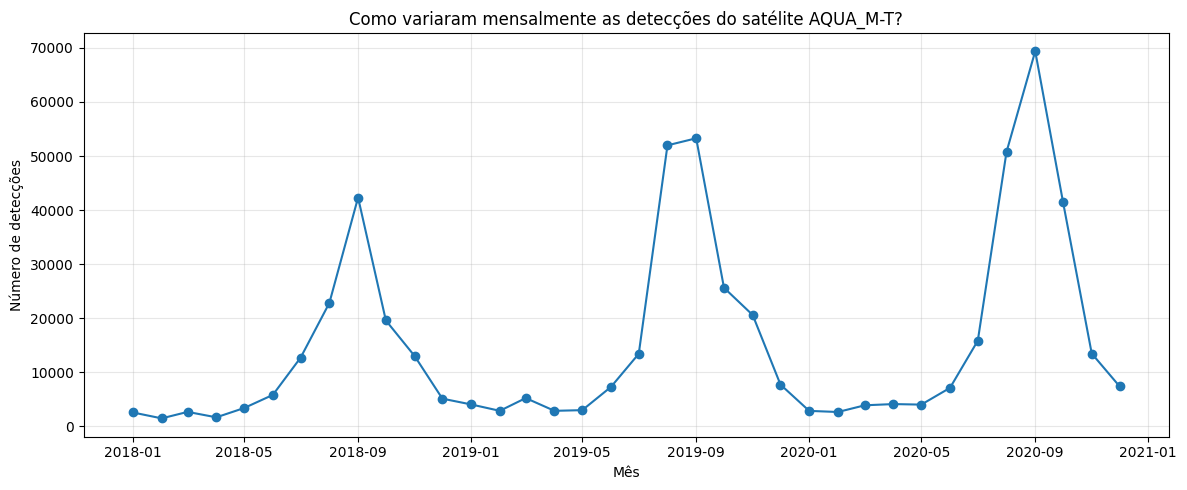

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(serie_mensal["data"], serie_mensal["focos"], marker="o")
plt.title("Como variaram mensalmente as detecções do satélite AQUA_M-T?")
plt.xlabel("Mês")
plt.ylabel("Número de detecções")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura preliminar:** As detecções mensais do satélite AQUA_M-T aumentam principalmente entre julho e setembro nos três anos analisados e diminuem nos meses seguintes. O pico visual mais alto ocorre em setembro de 2020. A análise cobre somente 2018–2020 e conta detecções do satélite, não incêndios únicos.

In [19]:
consulta_ufs = f"""
SELECT estado, COUNT(*) AS deteccoes
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
GROUP BY estado
ORDER BY deteccoes DESC
"""

deteccoes_uf = duckdb.sql(consulta_ufs).df()
display(deteccoes_uf.head(10))

,estado,deteccoes
0,MATO GROSSO,96914
1,PARÁ,91059
2,MARANHÃO,49232
3,AMAZONAS,41003
4,TOCANTINS,33751
5,RONDÔNIA,32652
6,PIAUÍ,29642
7,MATO GROSSO DO SUL,26113
8,MINAS GERAIS,23462
9,ACRE,22621


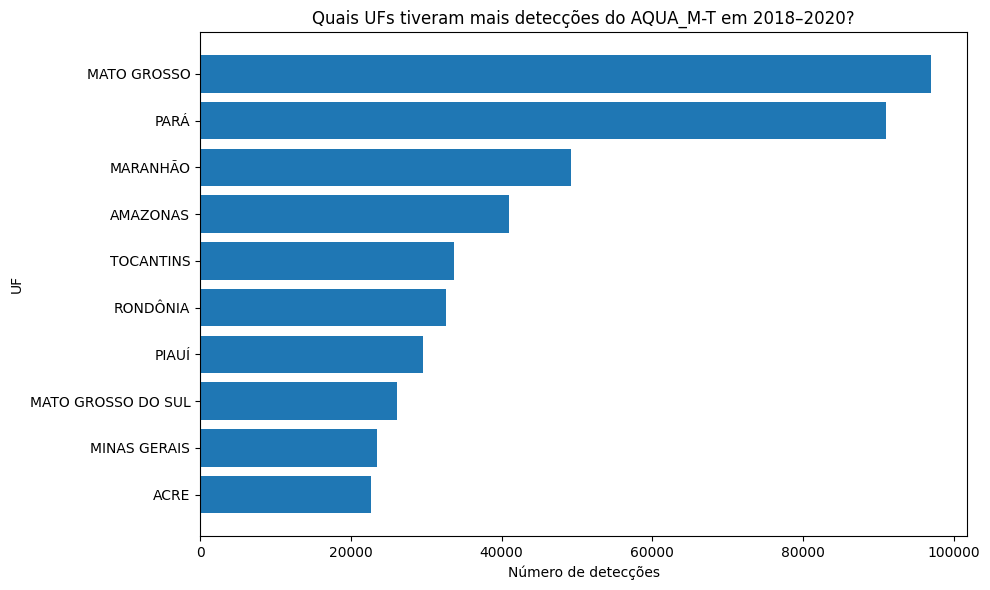

In [20]:
top_10_uf = deteccoes_uf.head(10).sort_values("deteccoes")

plt.figure(figsize=(10, 6))
plt.barh(top_10_uf["estado"], top_10_uf["deteccoes"])
plt.title("Quais UFs tiveram mais detecções do AQUA_M-T em 2018–2020?")
plt.xlabel("Número de detecções")
plt.ylabel("UF")
plt.tight_layout()
plt.show()

**Leitura preliminar:** No recorte 2018–2020 e usando o satélite AQUA_M-T, Mato Grosso teve o maior número de detecções (96.914), seguido pelo Pará (91.059). Essa comparação usa contagens absolutas e não considera a área ou a população de cada UF.

In [21]:
consulta_bioma_mes = f"""
SELECT
    bioma,
    CAST(SUBSTR(data_pas, 6, 2) AS INTEGER) AS mes,
    COUNT(*) AS deteccoes
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
  AND bioma IS NOT NULL
GROUP BY bioma, mes
ORDER BY bioma, mes
"""

bioma_mes = duckdb.sql(consulta_bioma_mes).df()
tabela_bioma_mes = (
    bioma_mes.pivot(index="bioma", columns="mes", values="deteccoes")
    .fillna(0)
    .reindex(columns=range(1, 13), fill_value=0)
)

display(tabela_bioma_mes)

mes,1,2,3,4,5,6,7,8,9,10,11,12
bioma,,,,,,,,,,,,
Amazônia,4083,3466,6406,3029,2485,6147,16949,70687,76798,35870,26523,8626
Caatinga,1047,166,139,98,174,420,1169,3668,8689,12424,7774,5100
Cerrado,2398,1520,2671,2461,4929,10501,16231,31054,56261,26840,7972,4327
Mata Atlântica,1303,1374,1616,1862,2071,2312,4976,11189,11017,6031,2661,1501
Pampa,87,162,321,442,402,218,336,1062,428,174,100,132
Pantanal,625,383,709,836,409,691,2368,7900,11778,5406,2094,633


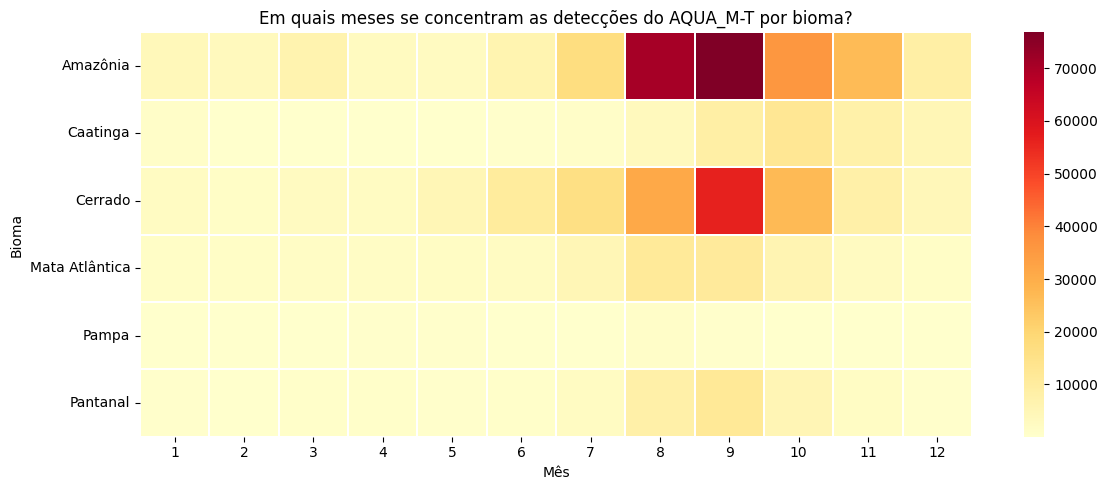

In [22]:
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.heatmap(tabela_bioma_mes, cmap="YlOrRd", linewidths=0.3)
plt.title("Em quais meses se concentram as detecções do AQUA_M-T por bioma?")
plt.xlabel("Mês")
plt.ylabel("Bioma")
plt.tight_layout()
plt.show()

**Leitura preliminar:** No período 2018–2020, as detecções do AQUA_M-T se concentraram principalmente em agosto e setembro na Amazônia e no Cerrado. Na Caatinga, o maior total ocorreu em outubro. O gráfico mostra contagens absolutas acumuladas nos três anos; não ajusta pela área dos biomas.

In [23]:
variaveis_numericas = [
    "numero_dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "frp"
]

colunas_com_sentinela = {
    "numero_dias_sem_chuva",
    "precipitacao",
    "risco_fogo"
}

resumos = []

for coluna in variaveis_numericas:
    filtro_sentinela = (
        f"AND {coluna} != -999"
        if coluna in colunas_com_sentinela
        else ""
    )

    consulta = f"""
    WITH dados AS (
        SELECT {coluna} AS valor
        FROM read_parquet(
            '{padrao_parquet}',
            union_by_name=true,
            hive_partitioning=false
        )
        WHERE satelite = 'AQUA_M-T'
          AND {coluna} IS NOT NULL
          {filtro_sentinela}
    ),
    quartis AS (
        SELECT
            quantile_cont(valor, 0.25) AS q1,
            quantile_cont(valor, 0.75) AS q3
        FROM dados
    )
    SELECT
        '{coluna}' AS variavel,
        COUNT(*) AS n,
        AVG(valor) AS media,
        MEDIAN(valor) AS mediana,
        STDDEV_SAMP(valor) AS desvio_padrao,
        MIN(valor) AS minimo,
        MAX(valor) AS maximo,
        quartis.q1,
        quartis.q3,
        SUM(
            CASE
                WHEN dados.valor < quartis.q1 - 1.5 * (quartis.q3 - quartis.q1)
                  OR dados.valor > quartis.q3 + 1.5 * (quartis.q3 - quartis.q1)
                THEN 1 ELSE 0
            END
        ) AS outliers_iqr
    FROM dados
    CROSS JOIN quartis
    GROUP BY quartis.q1, quartis.q3
    """

    resumos.append(duckdb.sql(consulta).df())

resumo_numerico = pd.concat(resumos, ignore_index=True)
display(resumo_numerico.round(2))

,variavel,n,media,mediana,desvio_padrao,minimo,maximo,q1,q3,outliers_iqr
0,numero_dias_sem_chuva,549797,21.25,8.0,29.15,0.0,120.0,3.0,26.0,66338.0
1,precipitacao,553800,0.71,0.0,2.97,0.0,125.5,0.0,0.1,103284.0
2,risco_fogo,549820,0.72,0.9,0.36,0.0,1.0,0.4,1.0,0.0
3,frp,552074,60.94,28.2,133.10,0.0,8589.8,15.1,58.5,55538.0


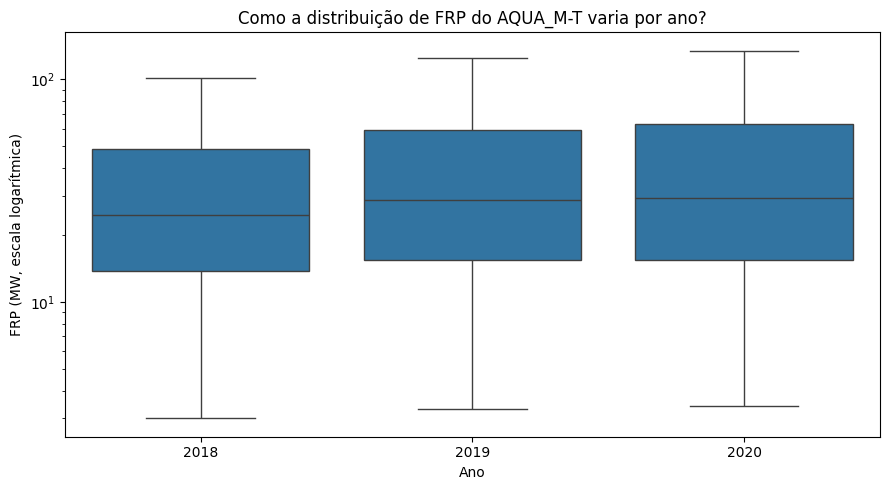

In [24]:
consulta_frp_ano = f"""
SELECT
    CAST(SUBSTR(data_pas, 1, 4) AS INTEGER) AS ano,
    frp
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
  AND frp IS NOT NULL
  AND frp > 0
"""

frp_por_ano = duckdb.sql(consulta_frp_ano).df()

frp_amostra = pd.concat(
    [
        grupo.sample(n=min(15_000, len(grupo)), random_state=42)
        for _, grupo in frp_por_ano.groupby("ano")
    ],
    ignore_index=True
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=frp_amostra,
    x="ano",
    y="frp",
    showfliers=False
)
plt.yscale("log")
plt.title("Como a distribuição de FRP do AQUA_M-T varia por ano?")
plt.xlabel("Ano")
plt.ylabel("FRP (MW, escala logarítmica)")
plt.tight_layout()
plt.show()

**Leitura preliminar:** A mediana e a faixa central de FRP parecem ligeiramente maiores em 2019 e 2020 do que em 2018, mas as distribuições se sobrepõem. O gráfico usa uma amostra de até 15 mil registros por ano, eixo logarítmico e não exibe os pontos extremos.

In [25]:
consulta_relacao = f"""
SELECT
    COUNT(*) AS registros_validos,
    CORR(precipitacao, risco_fogo) AS correlacao_pearson
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
  AND precipitacao IS NOT NULL
  AND precipitacao >= 0
  AND risco_fogo BETWEEN 0 AND 1
"""

relacao = duckdb.sql(consulta_relacao).df()
display(relacao)

consulta_amostra_relacao = f"""
SELECT precipitacao, risco_fogo
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
WHERE satelite = 'AQUA_M-T'
  AND precipitacao IS NOT NULL
  AND precipitacao >= 0
  AND risco_fogo BETWEEN 0 AND 1
ORDER BY RANDOM()
LIMIT 30000
"""

amostra_relacao = duckdb.sql(consulta_amostra_relacao).df()

,registros_validos,correlacao_pearson
0,549820,-0.371562


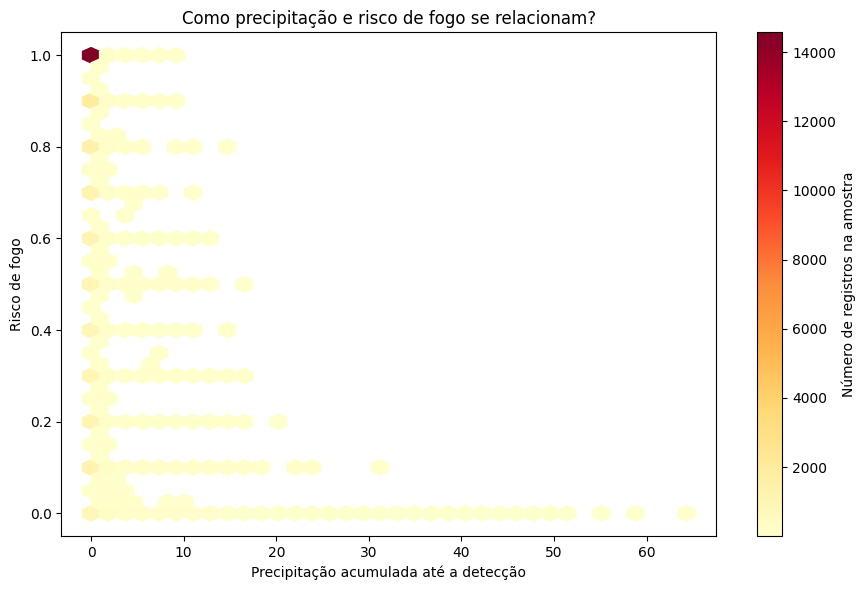

In [26]:
plt.figure(figsize=(9, 6))
grafico = plt.hexbin(
    amostra_relacao["precipitacao"],
    amostra_relacao["risco_fogo"],
    gridsize=35,
    mincnt=1,
    cmap="YlOrRd"
)
plt.colorbar(grafico, label="Número de registros na amostra")
plt.title("Como precipitação e risco de fogo se relacionam?")
plt.xlabel("Precipitação acumulada até a detecção")
plt.ylabel("Risco de fogo")
plt.tight_layout()
plt.show()

## Respostas preliminares às perguntas

1. **Como variam as detecções ao longo do ano?**  
   No AQUA_M-T, as detecções aumentam principalmente entre julho e setembro. O pico mensal visual mais alto do recorte ocorre em setembro de 2020.

2. **Quais UFs tiveram mais detecções?**  
   Entre 2018 e 2020, Mato Grosso registrou 96.914 detecções do AQUA_M-T e o Pará, 91.059. São contagens absolutas, sem ajuste por área ou população.

3. **A sazonalidade varia entre biomas?**  
   No acumulado dos três anos, Amazônia e Cerrado tiveram maiores contagens em agosto e setembro; na Caatinga, o maior total ocorreu em outubro.

4. **Os dados são comparáveis entre satélites?**  
   O arquivo contém 18 categorias de satélite. A proporção de valores ausentes em `frp` varia muito entre elas; por isso, comparações temporais devem manter o mesmo satélite. As análises temporais deste notebook usam AQUA_M-T.

5. **Quais UFs têm mais detecções por 100 mil habitantes?**  
   Resposta pendente: será calculada depois da integração com os dados populacionais do IBGE.

## Problemas de qualidade priorizados

| Prioridade | Achado | Evidência da EDA | Encaminhamento para a etapa de tratamento |
|---|---|---|---|
| Alta | Ausências de `frp` variam muito por satélite | Ausência de 100% em várias categorias e 94,36% em NOAA-20 | Preservar os registros; não imputar FRP sem justificativa; analisar FRP apenas onde houver medida |
| Alta | Códigos inválidos `-999` | 75.929 em `numero_dias_sem_chuva` e 144.728 em `risco_fogo` | Converter o código em ausente na base tratada e registrar as linhas afetadas |
| Média | Registros duplicados exatos | 1.182 linhas excedentes | Remover duplicatas exatas na base tratada e medir o efeito |
| Média | Tipo inconsistente entre partes do Parquet | `numero_dias_sem_chuva` aparece como inteiro e decimal | Harmonizar o tipo depois de tratar códigos inválidos |
| Média | Ausências explícitas em variáveis ambientais | 43.992 valores ausentes em cada uma de `numero_dias_sem_chuva`, `precipitacao` e `risco_fogo` | Manter ausentes e medir sua distribuição por ano |
| Baixa | Ausências em `bioma` | 74 registros nos três anos | Manter como ausente ou identificar como não informado; não inferir o bioma |
| Investigar | Definição de `id_area_industrial` não confirmada | A documentação consultada não esclarece o domínio | Não usar essa coluna nas análises até confirmar o significado |

A EDA não encontrou datas inválidas, coordenadas fora dos limites ou valores fora dos domínios verificados, desconsiderando os códigos `-999`.


In [27]:
consulta_dias_fracionarios = f"""
SELECT
    COUNT(*) AS total_registros,
    SUM(
        CASE
            WHEN numero_dias_sem_chuva IS NOT NULL
             AND numero_dias_sem_chuva != -999
             AND numero_dias_sem_chuva != FLOOR(numero_dias_sem_chuva)
            THEN 1 ELSE 0
        END
    ) AS valores_fracionarios
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
"""

dias_fracionarios = duckdb.sql(consulta_dias_fracionarios).df()
display(dias_fracionarios)

,total_registros,valores_fracionarios
0,11109371,0.0


In [28]:
con_limpeza = duckdb.connect()

con_limpeza.execute(f"""
CREATE OR REPLACE TEMP VIEW origem_distinta AS
SELECT DISTINCT *
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
""")

con_limpeza.execute("""
CREATE OR REPLACE TEMP VIEW silver_preview AS
SELECT
    CAST(latitude AS DOUBLE) AS latitude,
    CAST(longitude AS DOUBLE) AS longitude,
    CAST(data_pas AS TIMESTAMP) AS data_hora,
    CAST(satelite AS VARCHAR) AS satelite,
    CAST(pais AS VARCHAR) AS pais,
    CAST(estado AS VARCHAR) AS estado,
    CAST(municipio AS VARCHAR) AS municipio,
    CAST(bioma AS VARCHAR) AS bioma,
    CASE
        WHEN CAST(numero_dias_sem_chuva AS DOUBLE) = -999 THEN NULL
        ELSE CAST(numero_dias_sem_chuva AS BIGINT)
    END AS numero_dias_sem_chuva,
    CAST(precipitacao AS DOUBLE) AS precipitacao,
    CASE
        WHEN risco_fogo = -999 THEN NULL
        ELSE CAST(risco_fogo AS DOUBLE)
    END AS risco_fogo,
    CAST(id_area_industrial AS BIGINT) AS id_area_industrial,
    CAST(frp AS DOUBLE) AS frp,
    CAST(
        STRFTIME(CAST(data_pas AS TIMESTAMP), '%Y')
        AS INTEGER
    ) AS ano
FROM origem_distinta
""")

total_original = duckdb.sql(f"""
SELECT COUNT(*) AS linhas
FROM read_parquet(
    '{padrao_parquet}',
    union_by_name=true,
    hive_partitioning=false
)
""").df()

total_sem_duplicados = con_limpeza.sql("""
SELECT COUNT(*) AS linhas FROM origem_distinta
""").df()

total_preview = con_limpeza.sql("""
SELECT COUNT(*) AS linhas FROM silver_preview
""").df()

print("Linhas originais:")
display(total_original)

print("Após remover duplicados exatos:")
display(total_sem_duplicados)

print("Na prévia tratada:")
display(total_preview)

print("Exemplo da prévia:")
display(con_limpeza.sql("SELECT * FROM silver_preview LIMIT 5").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Linhas originais:


,linhas
0,11109371


Após remover duplicados exatos:


,linhas
0,11108189


Na prévia tratada:


,linhas
0,11108189


Exemplo da prévia:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,latitude,longitude,data_hora,satelite,pais,estado,municipio,bioma,numero_dias_sem_chuva,precipitacao,risco_fogo,id_area_industrial,frp,ano
0,-3.70291,-50.17225,2018-10-15 04:24:00,NPP-375D,Brasil,PARÁ,PACAJÁ,Amazônia,37,0.0,1.0,0,1.2,2018
1,-3.70360,-49.99146,2018-10-15 04:24:00,NPP-375D,Brasil,PARÁ,TUCURUÍ,Amazônia,6,0.2,1.0,0,2.7,2018
2,-3.70470,-53.92881,2018-10-15 04:24:00,NPP-375D,Brasil,PARÁ,URUARÁ,Amazônia,15,0.0,1.0,0,0.8,2018
3,-3.70515,-53.92609,2018-10-15 04:24:00,NPP-375D,Brasil,PARÁ,URUARÁ,Amazônia,15,0.0,1.0,0,0.5,2018
4,-5.05995,-49.71571,2018-10-15 04:24:00,NPP-375D,Brasil,PARÁ,ITUPIRANGA,Amazônia,8,0.0,1.0,0,1.7,2018


In [29]:
from pathlib import Path
import pandas as pd

TRATADOS = SILVER / "focos_tratados"
pasta_docs_drive = PROJETO / "docs"
pasta_docs_drive.mkdir(parents=True, exist_ok=True)

if TRATADOS.exists() and any(TRATADOS.rglob("*.parquet")):
    raise FileExistsError(
        f"Já existem Parquet em {TRATADOS}. "
        "Não vou sobrescrevê-los."
    )

TRATADOS.parent.mkdir(parents=True, exist_ok=True)

# Grava os dados tratados em Parquet particionado pelo ano.
con_limpeza.execute(f"""
COPY (
    SELECT * FROM silver_preview
)
TO '{TRATADOS.as_posix()}'
(
    FORMAT PARQUET,
    COMPRESSION SNAPPY,
    PARTITION_BY (ano)
)
""")

# Confere o total gravado.
padrao_tratados = str(TRATADOS / "**" / "*.parquet").replace("\\", "/")
total_gravado = duckdb.sql(f"""
SELECT COUNT(*) AS linhas
FROM read_parquet(
    '{padrao_tratados}',
    union_by_name=true,
    hive_partitioning=true
)
""").df()

print("Parquet tratados salvos em:", TRATADOS)
print("Total gravado:")
display(total_gravado)

# Conta os valores que foram transformados ou mantidos.
contagens_limpeza = con_limpeza.sql("""
SELECT
    COUNT(*) AS total_distinto,
    SUM(CASE WHEN CAST(numero_dias_sem_chuva AS DOUBLE) = -999
             THEN 1 ELSE 0 END) AS dias_sem_chuva_sentinela,
    SUM(CASE WHEN risco_fogo = -999
             THEN 1 ELSE 0 END) AS risco_fogo_sentinela,
    SUM(CASE WHEN frp IS NULL
             THEN 1 ELSE 0 END) AS frp_ausente,
    SUM(CASE WHEN bioma IS NULL
             THEN 1 ELSE 0 END) AS bioma_ausente
FROM origem_distinta
""").df().iloc[0]

linhas_antes = int(total_original.iloc[0]["linhas"])
linhas_depois = int(total_preview.iloc[0]["linhas"])
duplicatas_removidas = linhas_antes - linhas_depois

log_limpeza = pd.DataFrame([
    {
        "problema": "Duplicados exatos",
        "decisao": "Remover duplicatas exatas",
        "justificativa": "As linhas eram idênticas em todas as colunas.",
        "linhas_antes": linhas_antes,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": duplicatas_removidas
    },
    {
        "problema": "Código -999 em numero_dias_sem_chuva",
        "decisao": "Converter -999 em ausente",
        "justificativa": "O INPE documenta -999 como valor inválido; as linhas foram mantidas.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": int(contagens_limpeza["dias_sem_chuva_sentinela"])
    },
    {
        "problema": "Código -999 em risco_fogo",
        "decisao": "Converter -999 em ausente",
        "justificativa": "O INPE documenta -999 como valor inválido; as linhas foram mantidas.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": int(contagens_limpeza["risco_fogo_sentinela"])
    },
    {
        "problema": "Ausências em frp",
        "decisao": "Manter ausentes sem imputação",
        "justificativa": "A ausência varia por satélite e pode ser estrutural.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": int(contagens_limpeza["frp_ausente"])
    },
    {
        "problema": "Ausências em bioma",
        "decisao": "Manter ausentes sem inferir categoria",
        "justificativa": "Não há informação suficiente para preencher o bioma.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": int(contagens_limpeza["bioma_ausente"])
    },
    {
        "problema": "Candidatos a outlier pelo IQR",
        "decisao": "Manter os valores",
        "justificativa": "O critério IQR sinaliza extremos, mas não comprova erro.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": 0
    },
    {
        "problema": "Tipos inconsistentes entre partes",
        "decisao": "Padronizar tipos e converter data_pas para data_hora",
        "justificativa": "A coluna numero_dias_sem_chuva não apresentou valores fracionários.",
        "linhas_antes": linhas_depois,
        "linhas_depois": linhas_depois,
        "linhas_afetadas": linhas_depois
    }
])

arquivo_log = pasta_docs_drive / "log_limpeza.csv"
log_limpeza.to_csv(arquivo_log, index=False)

print("Log salvo em:", arquivo_log)
display(log_limpeza)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Parquet tratados salvos em: /content/drive/MyDrive/projeto-queimadas/data/silver/focos_tratados
Total gravado:


,linhas
0,11108189


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Log salvo em: /content/drive/MyDrive/projeto-queimadas/docs/log_limpeza.csv


,problema,decisao,justificativa,linhas_antes,linhas_depois,linhas_afetadas
0,Duplicados exatos,Remover duplicatas exatas,As linhas eram idênticas em todas as colunas.,11109371,11108189,1182
1,Código -999 em numero_dias_sem_chuva,Converter -999 em ausente,O INPE documenta -999 como valor inválido; as ...,11108189,11108189,75915
2,Código -999 em risco_fogo,Converter -999 em ausente,O INPE documenta -999 como valor inválido; as ...,11108189,11108189,144672
3,Ausências em frp,Manter ausentes sem imputação,A ausência varia por satélite e pode ser estru...,11108189,11108189,5952753
4,Ausências em bioma,Manter ausentes sem inferir categoria,Não há informação suficiente para preencher o ...,11108189,11108189,74
5,Candidatos a outlier pelo IQR,Manter os valores,"O critério IQR sinaliza extremos, mas não comp...",11108189,11108189,0
6,Tipos inconsistentes entre partes,Padronizar tipos e converter data_pas para dat...,A coluna numero_dias_sem_chuva não apresentou ...,11108189,11108189,11108189


In [30]:
from google.colab import files
files.download(str(arquivo_log))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
url_ibge = (
    "https://apisidra.ibge.gov.br/values/"
    "t/6579/n3/all/v/9324/p/2018-2020"
)

resposta_ibge = requests.get(url_ibge, timeout=120)
resposta_ibge.raise_for_status()

dados_ibge = resposta_ibge.json()
populacao_ibge_raw = pd.DataFrame(dados_ibge[1:])

arquivo_ibge_raw = BRONZE / "ibge_populacao_uf_2018_2020.json"
arquivo_ibge_raw.write_text(
    resposta_ibge.text,
    encoding="utf-8"
)

print("Colunas retornadas pela API:")
print(populacao_ibge_raw.columns.tolist())

print("\nPrimeiras linhas:")
display(populacao_ibge_raw.head())

Colunas retornadas pela API:
['NC', 'NN', 'MC', 'MN', 'V', 'D1C', 'D1N', 'D2C', 'D2N', 'D3C', 'D3N']

Primeiras linhas:


,NC,NN,MC,MN,V,D1C,D1N,D2C,D2N,D3C,D3N
0,3,Unidade da Federação,45,Pessoas,1757589,11,Rondônia,9324,População residente estimada,2018,2018
1,3,Unidade da Federação,45,Pessoas,1777225,11,Rondônia,9324,População residente estimada,2019,2019
2,3,Unidade da Federação,45,Pessoas,1796460,11,Rondônia,9324,População residente estimada,2020,2020
3,3,Unidade da Federação,45,Pessoas,869265,12,Acre,9324,População residente estimada,2018,2018
4,3,Unidade da Federação,45,Pessoas,881935,12,Acre,9324,População residente estimada,2019,2019


In [32]:
import unicodedata

def normalizar_estado(nome):
    texto = unicodedata.normalize("NFKD", str(nome))
    texto = "".join(
        caractere for caractere in texto
        if not unicodedata.combining(caractere)
    )
    return texto.strip().upper()


# Preparar a população do SIDRA
pop_uf = populacao_ibge_raw[
    ["D1C", "D1N", "D3C", "V"]
].copy()

pop_uf = pop_uf.rename(columns={
    "D1C": "codigo_uf",
    "D1N": "estado_ibge",
    "D3C": "ano",
    "V": "populacao"
})

pop_uf["codigo_uf"] = pop_uf["codigo_uf"].astype(str).str.zfill(2)
pop_uf["ano"] = pd.to_numeric(pop_uf["ano"]).astype(int)
pop_uf["populacao"] = pd.to_numeric(pop_uf["populacao"]).astype("int64")
pop_uf["estado_chave"] = pop_uf["estado_ibge"].map(normalizar_estado)


# Agregar detecções do satélite de referência por UF e ano
padrao_silver = str(TRATADOS / "**" / "*.parquet").replace("\\", "/")

consulta_uf_ano = f"""
SELECT estado, ano, COUNT(*) AS deteccoes
FROM read_parquet(
    '{padrao_silver}',
    union_by_name=true,
    hive_partitioning=true
)
WHERE satelite = 'AQUA_M-T'
GROUP BY estado, ano
"""

focos_uf_ano = duckdb.sql(consulta_uf_ano).df()
focos_uf_ano["estado_chave"] = focos_uf_ano["estado"].map(normalizar_estado)
focos_uf_ano["ano"] = focos_uf_ano["ano"].astype(int)


# Conferir a junção sem preencher valores ausentes ainda
integracao_teste = pop_uf.merge(
    focos_uf_ano[["estado_chave", "ano", "deteccoes"]],
    on=["estado_chave", "ano"],
    how="left",
    indicator=True
)

print("Linhas de população retornadas:", len(pop_uf))
print("Correspondências encontradas:")
display(integracao_teste["_merge"].value_counts().to_frame("quantidade"))

print("UFs/anos sem correspondência:")
display(
    integracao_teste.loc[
        integracao_teste["_merge"] != "both",
        ["codigo_uf", "estado_ibge", "ano", "_merge"]
    ]
)

Linhas de população retornadas: 81
Correspondências encontradas:


,quantidade
_merge,
both,81
left_only,0
right_only,0


UFs/anos sem correspondência:


,codigo_uf,estado_ibge,ano,_merge


In [33]:
integrada = integracao_teste.drop(columns="_merge").copy()

integrada["deteccoes"] = integrada["deteccoes"].astype("int64")
integrada["focos_por_100_mil"] = (
    integrada["deteccoes"] / integrada["populacao"] * 100_000
)

GOLD.mkdir(parents=True, exist_ok=True)

arquivo_integrado_csv = GOLD / "focos_pop_uf_2018_2020.csv"
arquivo_integrado_parquet = GOLD / "focos_pop_uf_2018_2020.parquet"

integrada.to_csv(arquivo_integrado_csv, index=False)
integrada.to_parquet(
    arquivo_integrado_parquet,
    index=False,
    compression="snappy"
)

print("Tabela integrada salva em:")
print(arquivo_integrado_csv)
print(arquivo_integrado_parquet)

print("\nMaiores taxas por UF-ano:")
display(
    integrada.sort_values(
        "focos_por_100_mil",
        ascending=False
    ).head(10)
)

Tabela integrada salva em:
/content/drive/MyDrive/projeto-queimadas/data/gold/focos_pop_uf_2018_2020.csv
/content/drive/MyDrive/projeto-queimadas/data/gold/focos_pop_uf_2018_2020.parquet

Maiores taxas por UF-ano:


,codigo_uf,estado_ibge,ano,populacao,estado_chave,deteccoes,focos_por_100_mil
74,51,Mato Grosso,2020,3526220,MATO GROSSO,47711,1353.035262
5,12,Acre,2020,894470,ACRE,9193,1027.759455
73,51,Mato Grosso,2019,3484466,MATO GROSSO,31169,894.512961
19,17,Tocantins,2019,1572866,TOCANTINS,13625,866.253069
10,14,Roraima,2019,605761,RORAIMA,4784,789.750413
4,12,Acre,2019,881935,ACRE,6802,771.258653
3,12,Acre,2018,869265,ACRE,6626,762.253168
20,17,Tocantins,2020,1590248,TOCANTINS,12093,760.447427
1,11,Rondônia,2019,1777225,RONDONIA,11233,632.052779
2,11,Rondônia,2020,1796460,RONDONIA,11157,621.054741


In [35]:
import zipfile
import geopandas as gpd

url_malha_zip = (
    "https://geoftp.ibge.gov.br/organizacao_do_territorio/"
    "malhas_territoriais/malhas_municipais/"
    "municipio_2020/Brasil/BR/BR_UF_2020.zip"
)

arquivo_malha_zip = BRONZE / "malha_ufs_ibge_2020.zip"

resposta_malha = requests.get(
    url_malha_zip,
    stream=True,
    timeout=(20, 180)
)
resposta_malha.raise_for_status()

with open(arquivo_malha_zip, "wb") as destino:
    for bloco in resposta_malha.iter_content(chunk_size=1024 * 1024):
        if bloco:
            destino.write(bloco)

pasta_malha = BRONZE / "malha_ufs_ibge_2020"
pasta_malha.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(arquivo_malha_zip) as pacote:
    caminho_shp_no_zip = next(
        nome for nome in pacote.namelist()
        if nome.lower().endswith(".shp")
    )
    pacote.extractall(pasta_malha)

arquivo_shp = pasta_malha / caminho_shp_no_zip
malha_ufs = gpd.read_file(arquivo_shp)

print("Shapefile:", arquivo_shp)
print("Colunas da malha:", malha_ufs.columns.tolist())
display(malha_ufs.head())

Shapefile: /content/drive/MyDrive/projeto-queimadas/data/bronze/malha_ufs_ibge_2020/BR_UF_2020.shp
Colunas da malha: ['CD_UF', 'NM_UF', 'SIGLA_UF', 'NM_REGIAO', 'geometry']


,CD_UF,NM_UF,SIGLA_UF,NM_REGIAO,geometry
0,11,Rondônia,RO,Norte,"POLYGON ((-65.3815 -10.42907, -65.38013 -10.42..."
1,12,Acre,AC,Norte,"POLYGON ((-71.07772 -9.82774, -71.07817 -9.828..."
2,13,Amazonas,AM,Norte,"POLYGON ((-69.83766 -3.68659, -69.82555 -3.620..."
3,14,Roraima,RR,Norte,"POLYGON ((-63.96008 2.47313, -63.96041 2.47416..."
4,15,Pará,PA,Norte,"MULTIPOLYGON (((-51.43248 -0.47334, -51.42949 ..."


Correspondências no mapa:


,quantidade
_merge,
both,27
left_only,0
right_only,0


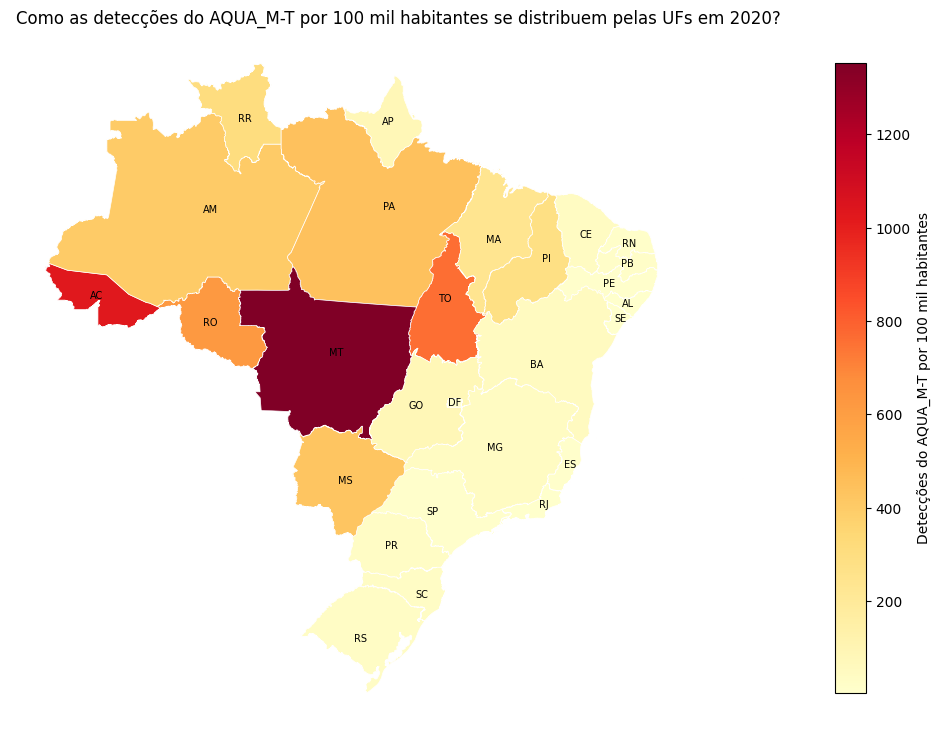

In [37]:
dados_mapa = integrada.loc[integrada["ano"] == 2020].copy()

malha_ufs["codigo_uf_num"] = pd.to_numeric(
    malha_ufs["CD_UF"]
).astype("int64")

dados_mapa["codigo_uf_num"] = pd.to_numeric(
    dados_mapa["codigo_uf"]
).astype("int64")

gdf_mapa = malha_ufs.merge(
    dados_mapa,
    on="codigo_uf_num",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Correspondências no mapa:")
display(gdf_mapa["_merge"].value_counts().to_frame("quantidade"))

fig, ax = plt.subplots(figsize=(10, 10))

gdf_mapa.plot(
    column="focos_por_100_mil",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Detecções do AQUA_M-T por 100 mil habitantes",
        "shrink": 0.65
    },
    ax=ax
)

pontos_rotulo = gdf_mapa.geometry.representative_point()

for x, y, sigla in zip(
    pontos_rotulo.x,
    pontos_rotulo.y,
    gdf_mapa["SIGLA_UF"]
):
    ax.text(x, y, sigla, ha="center", va="center", fontsize=7)

ax.set_title(
    "Como as detecções do AQUA_M-T por 100 mil habitantes se distribuem pelas UFs em 2020?"
)
ax.axis("off")
plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ano,linhas_antes,linhas_depois,linhas_removidas
0,2018,1826081,1826038,43
1,2019,4070300,4070272,28
2,2020,5212990,5211879,1111


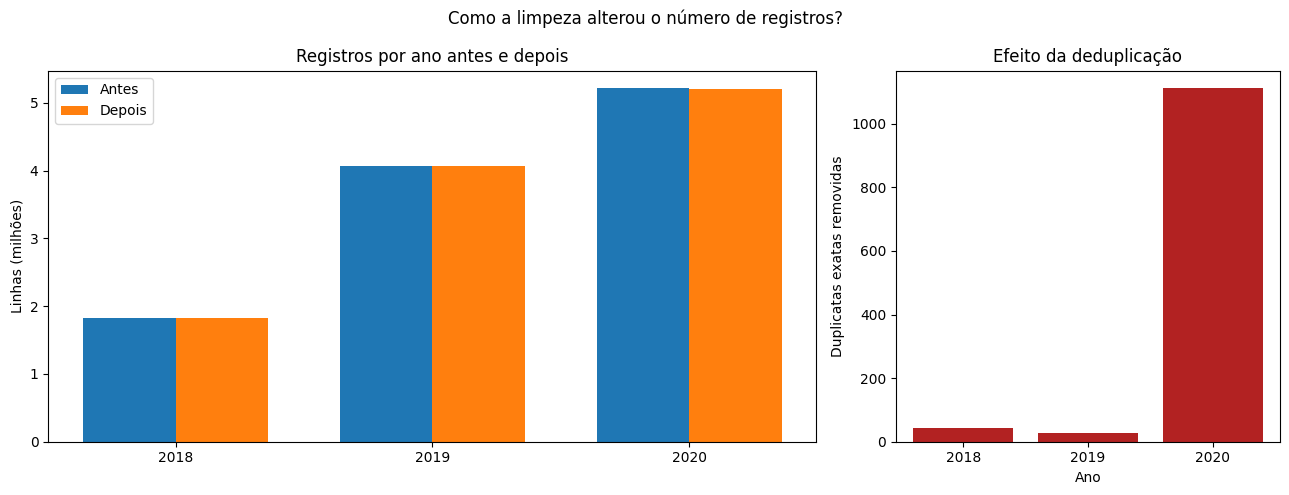

In [38]:
import numpy as np

padrao_bruto = str(
    PARQUET_BRONZE / "ano=*" / "*.parquet"
).replace("\\", "/")

padrao_tratado = str(
    TRATADOS / "**" / "*.parquet"
).replace("\\", "/")

antes_por_ano = duckdb.sql(f"""
SELECT
    CAST(SUBSTR(data_pas, 1, 4) AS INTEGER) AS ano,
    COUNT(*) AS linhas_antes
FROM read_parquet(
    '{padrao_bruto}',
    union_by_name=true,
    hive_partitioning=false
)
GROUP BY ano
ORDER BY ano
""").df()

depois_por_ano = duckdb.sql(f"""
SELECT
    ano,
    COUNT(*) AS linhas_depois
FROM read_parquet(
    '{padrao_tratado}',
    union_by_name=true,
    hive_partitioning=true
)
GROUP BY ano
ORDER BY ano
""").df()

comparacao_limpeza = antes_por_ano.merge(
    depois_por_ano,
    on="ano",
    validate="one_to_one"
)
comparacao_limpeza["linhas_removidas"] = (
    comparacao_limpeza["linhas_antes"]
    - comparacao_limpeza["linhas_depois"]
)

display(comparacao_limpeza)

posicoes = np.arange(len(comparacao_limpeza))
largura = 0.36

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13, 5),
    gridspec_kw={"width_ratios": [2, 1]}
)

ax1.bar(
    posicoes - largura / 2,
    comparacao_limpeza["linhas_antes"] / 1_000_000,
    largura,
    label="Antes"
)
ax1.bar(
    posicoes + largura / 2,
    comparacao_limpeza["linhas_depois"] / 1_000_000,
    largura,
    label="Depois"
)
ax1.set_xticks(posicoes, comparacao_limpeza["ano"])
ax1.set_ylabel("Linhas (milhões)")
ax1.set_title("Registros por ano antes e depois")
ax1.legend()

ax2.bar(
    comparacao_limpeza["ano"].astype(str),
    comparacao_limpeza["linhas_removidas"],
    color="firebrick"
)
ax2.set_xlabel("Ano")
ax2.set_ylabel("Duplicatas exatas removidas")
ax2.set_title("Efeito da deduplicação")

fig.suptitle("Como a limpeza alterou o número de registros?")
plt.tight_layout()
plt.show()

**Leitura preliminar:** A limpeza removeu 1.182 duplicatas exatas: 43 de 2018, 28 de 2019 e 1.111 de 2020. Isso equivale a cerca de 0,011% dos registros originais. As substituições de códigos inválidos por ausentes e a padronização de tipos mantiveram as linhas.

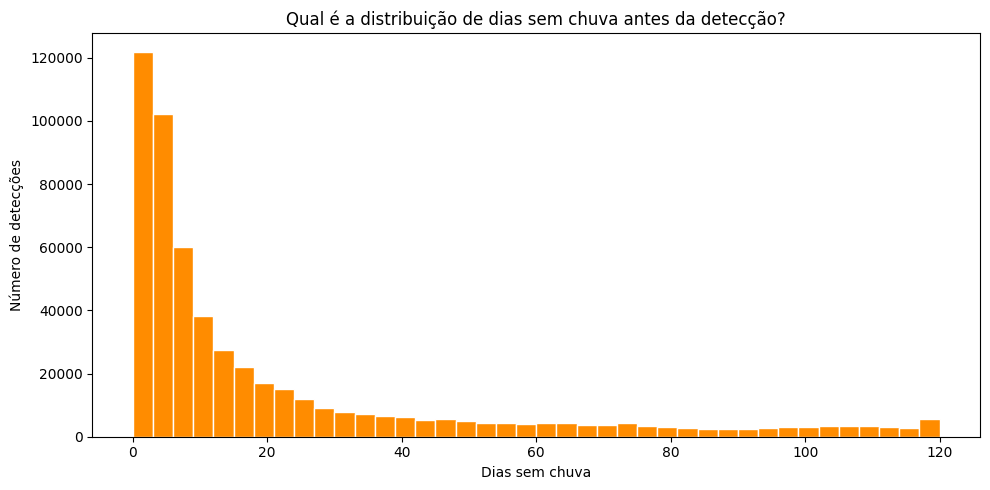

Registros válidos no histograma: 549,795


In [39]:
consulta_dias_hist = f"""
SELECT numero_dias_sem_chuva
FROM read_parquet(
    '{padrao_silver}',
    union_by_name=true,
    hive_partitioning=true
)
WHERE satelite = 'AQUA_M-T'
  AND numero_dias_sem_chuva IS NOT NULL
  AND numero_dias_sem_chuva >= 0
"""

dias_hist = duckdb.sql(consulta_dias_hist).df()

plt.figure(figsize=(10, 5))
plt.hist(
    dias_hist["numero_dias_sem_chuva"],
    bins=40,
    color="darkorange",
    edgecolor="white"
)
plt.title("Qual é a distribuição de dias sem chuva antes da detecção?")
plt.xlabel("Dias sem chuva")
plt.ylabel("Número de detecções")
plt.tight_layout()
plt.show()

print("Registros válidos no histograma:", f"{len(dias_hist):,}")

**Leitura preliminar:** A distribuição é assimétrica à direita. A mediana é de 8 dias sem chuva e a média é de 21,25 dias; a cauda chega a 120 dias. O histograma descreve o contexto dos registros, sem demonstrar que a falta de chuva causou as detecções.